# 06. Tool Calling Single Agent
## 학습 목표
- 모델의 도구 **호출 요청**과 실제 Python 도구 **실행**을 구분한다.
- `AgentState`, `ToolNode`, `tools_condition`으로 Agent Loop를 구성한다.

**준비:** OpenAI Tool Calling을 지원하는 모델과 API 키가 필요하다. 기본 모델은 `gpt-4o-mini`이다. 모델 선택과 문구는 호출마다 달라질 수 있다.

## 실습 A. 도구 호출 요청 보기
실행 전 예측: `bind_tools()`를 붙인 모델을 호출하면 Python 함수가 자동 실행될까? `AIMessage.tool_calls`에는 무엇이 들어갈까?

In [1]:
from langchain_core.globals import set_llm_cache, get_llm_cache
from langchain_core.caches import InMemoryCache
from common.ai_model import get_llm_model

# 동일한 프롬프트+모델 파라미터로 호출하면 API를 다시 부르지 않고
# 캐시된 응답을 즉시 반환한다. 커널을 재시작하면 캐시는 사라진다.
set_llm_cache(InMemoryCache())

llm_options = {"model": "gpt-4o-mini", "temperature": 0}

llm = get_llm_model(**llm_options)
print("사용 모델:", llm_options["model"])
print("캐시 종류:", type(get_llm_cache()).__name__)

사용 모델: gpt-4o-mini
캐시 종류: InMemoryCache


In [4]:
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, ToolMessage

# 도구 선언
@tool
def add_numbers(a: int, b: int) -> int:
    """두 정수를 더한다."""
    return a + b

# 도구 선언
@tool
def multiply_numbers(a: int, b: int) -> int:
    """두 정수를 곱한다."""
    return a * b

# 도구를 LLM에 바인딩
tools = [add_numbers, multiply_numbers]
llm_with_tools = llm.bind_tools(tools)

# LLM에 바인딩된 도구를 이름으로 조회할 수 있도록 딕셔너리 생성
tools_by_name = {item.name: item for item in tools}
tools_by_name

{'add_numbers': StructuredTool(name='add_numbers', description='두 정수를 더한다.', args_schema=<class 'langchain_core.utils.pydantic.add_numbers'>, func=<function add_numbers at 0x70a9389774c0>),
 'multiply_numbers': StructuredTool(name='multiply_numbers', description='두 정수를 곱한다.', args_schema=<class 'langchain_core.utils.pydantic.multiply_numbers'>, func=<function multiply_numbers at 0x70a938977420>)}

In [5]:
# 기본 바인딩(llm_with_tools)을 사용한다. 모델이 스스로 도구를 선택하며, 아직 함수는 실행되지 않는다.
response = llm_with_tools.invoke([HumanMessage(content="12와 8을 더해줘.")])

print("응답 자료형:", type(response).__name__)
print("LLM 도구 호출 요청:", response.tool_calls)

# 테스트
assert response.tool_calls

응답 자료형: AIMessage
LLM 도구 호출 요청: [{'name': 'add_numbers', 'args': {'a': 12, 'b': 8}, 'id': 'call_4yLgA94VPqHlESj9iEnHemnT', 'type': 'tool_call'}]


In [6]:
response

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 22, 'prompt_tokens': 80, 'total_tokens': 102, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 0, 'rejected_prediction_tokens': None, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.4-mini', 'system_fingerprint': None, 'id': 'resp_09c992a0711e58c5016acc854ceba487d0bd3a57ffd07fc895', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a12ee8-b487-75c2-8879-4b4c02889a3f-0', tool_calls=[{'name': 'add_numbers', 'args': {'a': 12, 'b': 8}, 'id': 'call_4yLgA94VPqHlESj9iEnHemnT', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 80, 'output_tokens': 22, 'total_tokens': 102, 'input_token_details': {'cache_read': 0, 'cache_crea

## 이해 확인
1. `AIMessage.tool_calls`가 존재하면 이미 Python 도구가 실행된 것인가?  
   **해설:** 아니다. 실습 A에서는 요청만 생성되고, 실제 실행은 실습 B의 `ToolNode`에서 일어난다.
2. 03번 점수 분기와 이 Agent의 도구 선택은 어떻게 다른가?  
   **해설:** 점수 분기는 개발자가 작성한 고정 조건이고, 도구 선택은 LLM 응답의 `tool_calls`를 따른다.

**핵심 정리:** `agent → tools → agent` Loop에서 모델이 도구 호출을 요청하고 ToolNode가 실행 결과를 메

## 실습 B. Graph 안의 Agent Loop
`AgentState`의 `messages`는 `Annotated[list, add_messages]`로 지정된 `add_messages` Reducer를 사용한다. 각 Node가 메시지를 추가하면 이전 대화가 유지된다. `tools_condition`은 마지막 `AIMessage`의 도구 호출 유무를 보고 경로를 정한다.

In [7]:
from typing import Annotated
from pydantic import BaseModel
from langgraph.graph import START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

# MessagesState(TypedDict) 대신 Pydantic으로 동일한 역할의 State를 정의한다.
# messages 필드는 add_messages Reducer로 누적된다.
class AgentState(BaseModel):
    messages: Annotated[list, add_messages]

# Agent Node를 정의한다. LLM이 도구 호출 요청을 생성하고, 실제 실행은 개발자가 수행한다.
def agent_node(state: AgentState) -> dict:
    # 첫 호출은 도구를 요청하게 하고, 도구 응답 뒤에는 최종 답변을 생성한다.
    if state.messages[-1].type == "tool":
        reply = llm.invoke(state.messages)
    else:
        reply = llm.bind_tools(tools, tool_choice="required", parallel_tool_calls=False).invoke(state.messages)
    return {"messages": [reply]}

# StateGraph를 구성한다. START -> agent -> tools -> agent 순환 구조이다.
builder = StateGraph(AgentState)

# Agent Node 추가
builder.add_node("agent", agent_node)

# Tools Node 추가
builder.add_node("tools", ToolNode(tools))

# START -> agent -> tools -> agent 순환 구조를 정의한다.
builder.add_edge(START, "agent")
builder.add_conditional_edges("agent", tools_condition)
builder.add_edge("tools", "agent")

# 그래프 컴파일
graph = builder.compile()

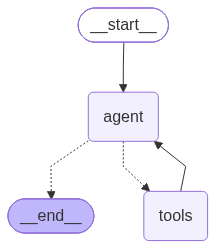

In [8]:
graph

### 질문 한개 테스트

In [9]:

question = "12와 8을 더해줘. add_numbers 도구를 사용해줘."
final_state = graph.invoke({"messages": [HumanMessage(content=question)]}, config={"recursion_limit": 10})

for message in final_state["messages"]:
      if message.type == "ai" and message.tool_calls:
          print("1. LLM 도구 호출 요청:", message.tool_calls)
      elif message.type == "tool":
          print("2. ToolNode 실행 결과:", message.content)
          print("3. ToolMessage:", type(message).__name__, "id=", message.tool_call_id)
      elif message.type == "ai":
          print("4. LLM 최종 답변:", message.content)

1. LLM 도구 호출 요청: [{'name': 'add_numbers', 'args': {'a': 12, 'b': 8}, 'id': 'call_8VP5IR4IdnYPMCgWiTg7En7r', 'type': 'tool_call'}]
2. ToolNode 실행 결과: 20
3. ToolMessage: ToolMessage id= call_8VP5IR4IdnYPMCgWiTg7En7r
4. LLM 최종 답변: 20


### 여러개 메시지를 한꺼번에 실행

In [ ]:
# 각 질문은 새 Graph 실행이다. 도구 선택은 모델의 판단이므로 결과를 관찰한다.
questions = ["12와 8을 더해줘. add_numbers 도구를 사용해줘.", "7과 9를 곱해줘. multiply_numbers 도구를 사용해줘."]
for question in questions:
    print("\n질문:", question)
    final_state = graph.invoke({"messages": [HumanMessage(content=question)]}, config={"recursion_limit": 10})
    
    for message in final_state["messages"]:
        if message.type == "ai" and message.tool_calls:
            print("1. LLM 도구 호출 요청:", message.tool_calls)
        elif message.type == "tool":
            print("2. ToolNode 실행 결과:", message.content)
            print("3. ToolMessage:", type(message).__name__, "id=", message.tool_call_id)
        elif message.type == "ai":
            print("4. LLM 최종 답변:", message.content)

    # 테스트 모델이 도구를 선택하지 않은 경우, 프롬프트와 Tool Calling 지원 여부를 확인한다.        
    assert any(message.type == "tool" for message in final_state["messages"]), "모델이 도구를 선택하지 않았다. 프롬프트와 Tool Calling 지원 여부를 확인한다."


질문: 12와 8을 더해줘. add_numbers 도구를 사용해줘.
1. LLM 도구 호출 요청: [{'name': 'add_numbers', 'args': {'a': 12, 'b': 8}, 'id': 'call_Ji2YCTWL2tQV8vldQGOefqyp', 'type': 'tool_call'}]
2. ToolNode 실행 결과: 20
3. ToolMessage: ToolMessage id= call_Ji2YCTWL2tQV8vldQGOefqyp
4. LLM 최종 답변: 12와 8을 더하면 20입니다.

질문: 7과 9를 곱해줘. multiply_numbers 도구를 사용해줘.
1. LLM 도구 호출 요청: [{'name': 'multiply_numbers', 'args': {'a': 7, 'b': 9}, 'id': 'call_x0VCSaFcHLo1y6pxooR0kth1', 'type': 'tool_call'}]
2. ToolNode 실행 결과: 63
3. ToolMessage: ToolMessage id= call_x0VCSaFcHLo1y6pxooR0kth1
4. LLM 최종 답변: 7과 9를 곱한 결과는 63입니다.


모델이 도구를 선택하지 않으면 질문 문구와 제공자의 Tool Calling 지원 여부를 확인한다. 도구를 실행하는 주체는 `ToolNode`이며, 모델은 호출할 도구와 인수를 제안한다.

## ToolCall의 원리 이해

```mermaid
sequenceDiagram
    participant U as 사용자
    participant Agent as Agent 노드
    participant LLM as LLM
    participant Tool as ToolNode (함수)

    U->>Agent: "12와 8을 더해줘"
    Agent->>LLM: 메시지 전달, 응답 요청
    LLM-->>Agent: 도구 호출 "요청"<br/>(add_numbers, a=12, b=8)
    Agent->>Tool: 요청받은 도구를 실제로 실행
    Tool-->>Agent: 결과 20
    Agent->>LLM: 결과(20)를 메시지로 다시 전달
    LLM-->>Agent: "합은 20입니다" (최종 답변)
    Agent-->>U: 최종 답변 전달
```


## 이해 확인
1. `AIMessage.tool_calls`가 존재하면 이미 Python 도구가 실행된 것인가?  
   **해설:** 아니다. 실습 A에서는 요청만 생성되고, 실제 실행은 실습 B의 `ToolNode`에서 일어난다.
2. 03번 점수 분기와 이 Agent의 도구 선택은 어떻게 다른가?  
   **해설:** 점수 분기는 개발자가 작성한 고정 조건이고, 도구 선택은 LLM 응답의 `tool_calls`를 따른다.

**핵심 정리:** `agent → tools → agent` Loop에서 모델이 도구 호출을 요청하고 ToolNode가 실행 결과를 메시지로 돌려준다.